## TH 6.2

Viết chương trình nhập danh sách sinh viên (họ tên, mã sinh viên, ngày sinh dạng `dd/mm/yyyy`) từ bàn phím, dừng khi người dùng bỏ trống họ tên (vòng `while True`, Chương \ref{ch:dieukhien}). Lưu vào một `DataFrame`, chuyển ngày sinh sang kiểu thời gian bằng `pd.to_datetime(…, format="%d/%m/%Y")`, tính cột `Tuoi` (số năm nguyên) từ ngày sinh đến mốc $01/01/2026$ (dùng `pd.Timestamp("2026-01-01")`, chia số ngày cho $365{,}25$ rồi lấy phần nguyên), ghi ra `students.xlsx` bằng `to_excel` (cần `openpyxl`) và đọc lại để kiểm tra. Dùng mốc cố định thay cho `pd.Timestamp.now()` để kết quả tái lập được.

In [4]:
import pandas as pd

rows = []
while True:
    ho_ten = input("Họ tên (bỏ trống để dừng): ").strip()
    if ho_ten == "":
        break
    ma_sv = input("Mã sinh viên: ").strip()
    ngay_sinh = input("Ngày sinh (dd/mm/yyyy): ").strip()
    rows.append({"HoTen": ho_ten, "MaSV": ma_sv, "NgaySinh": ngay_sinh})

df = pd.DataFrame(rows, columns=["HoTen", "MaSV", "NgaySinh"])

df["NgaySinh"] = pd.to_datetime(df["NgaySinh"], format="%d/%m/%Y")

moc = pd.Timestamp("2026-01-01")
df["Tuoi"] = ((moc - df["NgaySinh"]).dt.days / 365.25).astype(int)
print(df)

df.to_excel("students.xlsx", index=False)
df2 = pd.read_excel("students.xlsx", dtype={"MaSV": str})   
print(df2)
print(df2.dtypes)

Họ tên (bỏ trống để dừng):  nguyễn văn a
Mã sinh viên:  12312345
Ngày sinh (dd/mm/yyyy):  12/3/2000
Họ tên (bỏ trống để dừng):  nguyễn văn b
Mã sinh viên:  12354321
Ngày sinh (dd/mm/yyyy):  23/2/2002
Họ tên (bỏ trống để dừng):  nguyễn văn c
Mã sinh viên:  12323764
Ngày sinh (dd/mm/yyyy):  24/8/2000
Họ tên (bỏ trống để dừng):  


          HoTen      MaSV   NgaySinh  Tuoi
0  nguyễn văn a  12312345 2000-03-12    25
1  nguyễn văn b  12354321 2002-02-23    23
2  nguyễn văn c  12323764 2000-08-24    25
          HoTen      MaSV   NgaySinh  Tuoi
0  nguyễn văn a  12312345 2000-03-12    25
1  nguyễn văn b  12354321 2002-02-23    23
2  nguyễn văn c  12323764 2000-08-24    25
HoTen                  str
MaSV                   str
NgaySinh    datetime64[us]
Tuoi                 int64
dtype: object


## TH 6.3

Với `data/200heightsweights.csv` (chiều cao inch, cân nặng pound của $200$ người): (1) đổi tên cột thành `Height_in`, `Weight_lb`, đổi sang cm và kg, điền ô thiếu bằng trung bình cột, tính `BMI`, viết bằng method chaining; (2) đếm số người có $\mathrm{BMI}<18{,}5$; (3) dùng `pd.cut` chia chiều cao thành ba nhóm: `Thap` ($<170$ cm), `Trung binh` ($[170,175)$), `Cao` ($\ge175$) và đếm số người từng nhóm; (4) dùng `groupby` tính *tỉ lệ* người có $\mathrm{BMI}<18{,}5$ trong từng nhóm (gợi ý: trung bình của một cột logic là tỉ lệ `True`); (5) vẽ boxplot cân nặng theo nhóm chiều cao bằng Seaborn và lưu `box.png`; (6) nếu đã cài `plotly`, vẽ biểu đồ phân tán tương tác chiều cao -- cân nặng, tô màu theo nhóm.

['Index', 'Height(Inches)', 'Weight(Pounds)']
   Index  Height_in  Weight_lb  Height_cm  Weight_kg        BMI
0      1      65.78     112.99   167.0812  51.251402  18.359066
1      2      71.52     136.49   181.6608  61.910823  18.760488
2      3      69.40     153.03   176.2760  69.413240  22.338600
3      4      68.22     142.34   173.2788  64.564338  21.503138
4      5      67.79     144.30   172.1866  65.453379  22.076660
Số người BMI < 18,5: 50
Nhom
Thap          62
Trung binh    81
Cao           57
Name: count, dtype: int64
Nhom
Thap          0.258065
Trung binh    0.234568
Cao           0.263158
Name: Thieu_can, dtype: float64


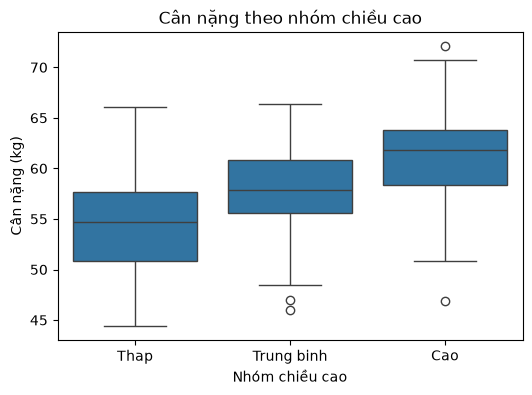

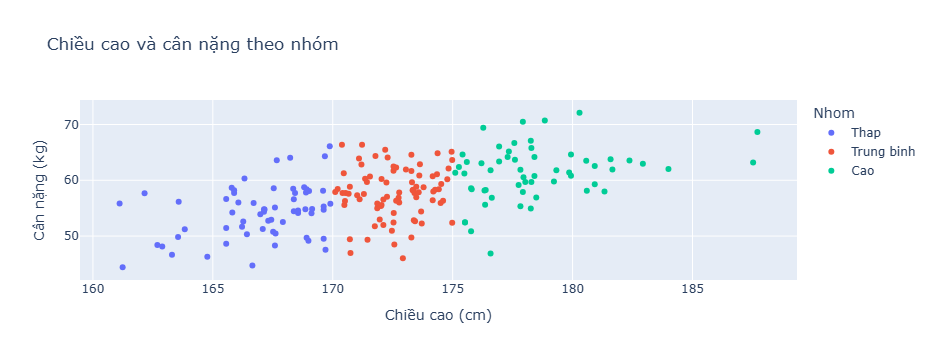

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

raw = pd.read_csv("200heightsweights.csv")
print(raw.columns.tolist())                     
h_col, w_col = raw.columns[-2:]                 

df = (
    raw
    .rename(columns={h_col: "Height_in", w_col: "Weight_lb"})
    .assign(
        Height_in=lambda d: d["Height_in"].fillna(d["Height_in"].mean()),
        Weight_lb=lambda d: d["Weight_lb"].fillna(d["Weight_lb"].mean()),
    )
    .assign(
        Height_cm=lambda d: d["Height_in"] * 2.54,
        Weight_kg=lambda d: d["Weight_lb"] * 0.45359237,
    )
    .assign(BMI=lambda d: d["Weight_kg"] / (d["Height_cm"] / 100) ** 2)
)
print(df.head())

print("Số người BMI < 18,5:", (df["BMI"] < 18.5).sum())

labels = ["Thap", "Trung binh", "Cao"]
df["Nhom"] = pd.cut(
    df["Height_cm"],
    bins=[-np.inf, 170, 175, np.inf],
    labels=labels,
    right=False,                                
)
print(df["Nhom"].value_counts().reindex(labels))

ti_le = (
    df.assign(Thieu_can=df["BMI"] < 18.5)
      .groupby("Nhom", observed=True)["Thieu_can"]
      .mean()
)
print(ti_le)

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Nhom", y="Weight_kg", order=labels)
plt.xlabel("Nhóm chiều cao")
plt.ylabel("Cân nặng (kg)")
plt.title("Cân nặng theo nhóm chiều cao")
plt.savefig("box.png", dpi=150, bbox_inches="tight")
plt.show()

try:
    import plotly.express as px
    fig = px.scatter(
        df, x="Height_cm", y="Weight_kg", color="Nhom",
        category_orders={"Nhom": labels},
        labels={"Height_cm": "Chiều cao (cm)", "Weight_kg": "Cân nặng (kg)"},
        title="Chiều cao và cân nặng theo nhóm",
    )
    fig.show()
except ImportError:
    print("Chưa cài plotly: pip install plotly")

## TH 6.4

Với `data/core_HRdata.csv` (nhân sự; các cột `Department`, `Sex`, `Pay Rate`, `Date of Hire`, `Performance Score`): (1) làm sạch tên phòng ban bằng `.str.strip()` (còn $6$ phòng ban); (2) lập bảng lương trung bình theo phòng ban (hàng) và giới tính (cột) bằng `groupby` và `unstack`; (3) chuyển `Date of Hire` sang kiểu thời gian, tính `Tham_nien` (số năm nguyên đến mốc $01/01/2017$, dùng `.dt.days // 365`) và in $5$ nhân viên có thâm niên cao nhất (sắp theo thâm niên giảm dần, ngang nhau thì theo tên nhân viên tăng dần, bằng `sort_values` với hai khoá); (4) thống kê số nhân viên theo `Performance Score`.

In [7]:
import pandas as pd

df = pd.read_csv("core_HRdata.csv")
print(df.columns.tolist())      

df["Department"] = df["Department"].str.strip()
print(df["Department"].nunique(), "phòng ban")   
print(df["Department"].unique())

bang_luong = (
    df.groupby(["Department", "Sex"])["Pay Rate"]
      .mean()
      .unstack()
)
print(bang_luong.round(2))

moc = pd.Timestamp("2017-01-01")
df["Date of Hire"] = pd.to_datetime(df["Date of Hire"])
df["Tham_nien"] = (moc - df["Date of Hire"]).dt.days // 365

ten_col = "Employee Name"

top5 = df.sort_values(
    by=["Tham_nien", ten_col],
    ascending=[False, True],          
).head(5)
print(top5[[ten_col, "Department", "Date of Hire", "Tham_nien"]])
print(df["Performance Score"].value_counts())

['Employee Name', 'Employee Number', 'State', 'Zip', 'DOB', 'Age', 'Sex', 'MaritalDesc', 'CitizenDesc', 'Hispanic/Latino', 'RaceDesc', 'Date of Hire', 'Date of Termination', 'Reason For Term', 'Employment Status', 'Department', 'Position', 'Pay Rate', 'Manager Name', 'Employee Source', 'Performance Score']
6 phòng ban
<ArrowStringArray>
[       'Admin Offices',     'Executive Office',                'IT/IS',
           'Production',                'Sales', 'Software Engineering']
Length: 6, dtype: str
Sex                   Female   Male
Department                         
Admin Offices          26.16  40.50
Executive Office       80.00    NaN
IT/IS                  42.54  46.74
Production             22.61  23.83
Sales                  55.68  55.38
Software Engineering   52.33  43.17
        Employee Name     Department Date of Hire  Tham_nien
282  Riordan, Michael          Sales   2006-01-09         10
165       Pitt, Brad      Production   2007-11-05          9
254  Thibaud, Kenneth 